# Logistic Regression Classification Project

## Project Overview

In this project, we will build a machine learning classification model using the Titanic dataset.

We will use the Universal Data Cleaner library to clean the input data, Seaborn to visualize the data, and Logistic Regression to predict passenger survival.

## Project Objectives

- Load and understand the Titanic dataset.
- Clean the input features using Universal Data Cleaner.
- Visualize important relationships using Seaborn.
- Prepare categorical and numerical features.
- Train a Logistic Regression classification model.
- Evaluate the model using classification metrics.

## Target Variable

The target column is `survived`.

- `0` = Passenger did not survive.
- `1` = Passenger survived.

In [10]:
# Data handling
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Universal Data Cleaner
from data_cleaner import DataCleaner, CleanerConfig

# Data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Machine learning model
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("All project libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("Seaborn version:", sns.__version__)

All project libraries imported successfully!
Pandas version: 3.0.6
Seaborn version: 0.13.2


## 1. Load the Dataset

We will use the Titanic dataset provided by Seaborn.

The dataset contains passenger information such as age, sex, passenger class, and fare.

Our goal is to predict whether a passenger survived using Logistic Regression.

In [11]:
# Load the Titanic dataset
df = sns.load_dataset("titanic")

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())

Dataset loaded successfully!
Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Separate Features and Target

The `survived` column is our target variable.

We will remove `alive` because it directly reveals the survival outcome. Keeping it as an input would cause data leakage.

We will split the data into training and testing sets before cleaning.

In [12]:
# Separate input features and target
X = df.drop(columns=["survived", "alive"]).copy()
y = df["survived"].copy()

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (712, 13)
Testing features: (179, 13)
Training target: (712,)
Testing target: (179,)


## 3. Clean the Data Using Universal Data Cleaner

We will use Universal Data Cleaner to prepare our input features.

The cleaner will learn its cleaning rules from the training data only. We will then apply those same rules to the testing data.

The target variable, `survived`, will remain separate from the cleaning process.

In [13]:
# Create the data cleaner
cleaner = DataCleaner(CleanerConfig())

# Learn cleaning rules from training data
cleaner.fit(X_train)

# Apply cleaning to training and testing data
X_train_clean = cleaner.transform(X_train)
X_test_clean = cleaner.transform(X_test)

# Check the results
print("Original training shape:", X_train.shape)
print("Cleaned training shape:", X_train_clean.shape)

print("\nMissing values after cleaning:")
print(X_train_clean.isnull().sum())

print("\nCleaning summary:")
print(cleaner.cleaning_summary())

Original training shape: (712, 13)
Cleaned training shape: (712, 13)

Missing values after cleaning:
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alone          0
dtype: int64

Cleaning summary:
         column         kind  missing_in_fit   fill_value  lower_bound  \
0        pclass      numeric               0          3.0       0.5000   
1           sex  categorical               0         male          NaN   
2           age      numeric             137         28.5      -6.0000   
3         sibsp      numeric               0          0.0      -1.5000   
4         parch      numeric               0          0.0         -inf   
5          fare      numeric               0      14.4542     -26.7605   
6      embarked  categorical               2            S          NaN   
7         class  categorical               0        Th

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns and relationships in the dataset.

We will use Seaborn to visualize passenger survival by sex and passenger class, and examine the relationship between age and survival.

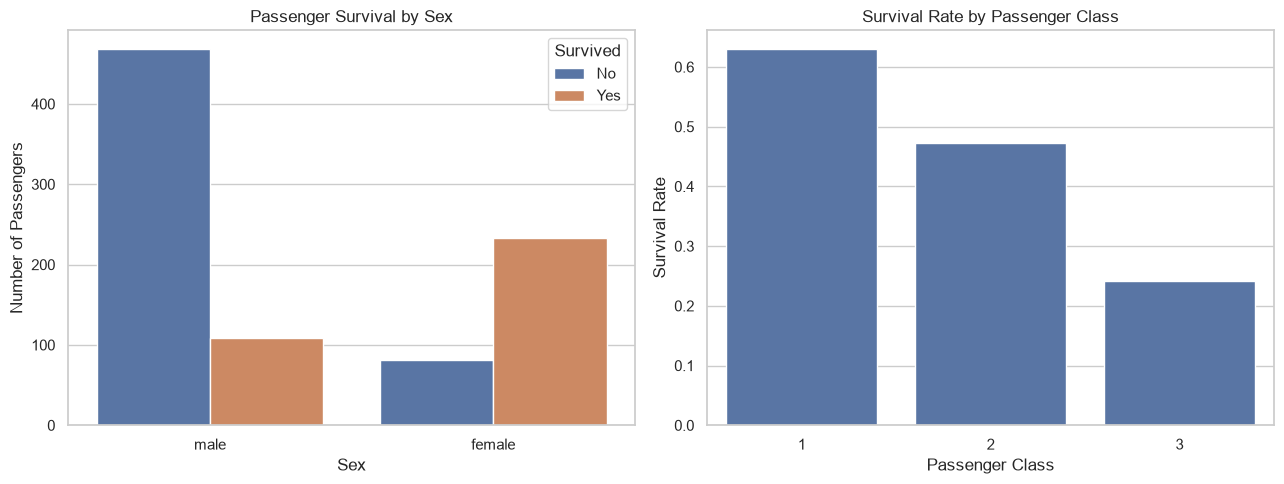

In [14]:
# Set the plot style
sns.set_theme(style="whitegrid")

# Create two visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Survival count by sex
sns.countplot(
    data=df,
    x="sex",
    hue="survived",
    ax=axes[0]
)
axes[0].set_title("Passenger Survival by Sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Number of Passengers")
axes[0].legend(title="Survived", labels=["No", "Yes"])

# Survival rate by passenger class
sns.barplot(
    data=df,
    x="pclass",
    y="survived",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Survival Rate by Passenger Class")
axes[1].set_xlabel("Passenger Class")
axes[1].set_ylabel("Survival Rate")

plt.tight_layout()
plt.show()

## 5. Prepare Features for Logistic Regression

Logistic Regression requires numerical input features.

We will identify numerical and categorical columns, scale numerical features, and convert categorical features into numerical values using One-Hot Encoding.

We will use a Scikit-learn pipeline so that preprocessing is learned from the training data and consistently applied to the test data.

In [15]:
# Identify numerical and categorical columns
numeric_features = X_train_clean.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_clean.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

# Create preprocessing pipelines
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical features: ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alone']


## 6. Train the Logistic Regression Model

We will combine data preprocessing and Logistic Regression into one pipeline. The model will learn from the training data and then make predictions on unseen test data.

In [17]:
# Create the Logistic Regression model
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]
)

# Train the model
model.fit(X_train_clean, y_train)

print("Model training completed successfully!")

Model training completed successfully!


## 7. Evaluate the Model

We will evaluate the model using Accuracy, ROC-AUC, and a Classification Report.

In [18]:
# Predict survival for the test data
y_pred = model.predict(X_test_clean)

# Get prediction probabilities
y_prob = model.predict_proba(X_test_clean)[:, 1]

# Display evaluation scores
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Did not survive", "Survived"]
    )
)

Accuracy: 0.827
ROC-AUC: 0.857

Classification Report:
                 precision    recall  f1-score   support

Did not survive       0.84      0.89      0.86       110
       Survived       0.81      0.72      0.76        69

       accuracy                           0.83       179
      macro avg       0.82      0.81      0.81       179
   weighted avg       0.83      0.83      0.82       179

